In [1]:
# ---- must come BEFORE any nltk.download call ----
import os
os.environ['NLTK_ALLOW_PROXIED_URLOPEN'] = '1'

import re, requests
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk import pos_tag, word_tokenize, ne_chunk
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import spacy

try:                           # belt and braces, in case the env var is ignored
    import nltk.pathsec
    nltk.pathsec.ALLOW_PROXIED_FETCH = True
except Exception:
    pass

RESOURCES = ['punkt', 'punkt_tab', 'stopwords', 'averaged_perceptron_tagger',
             'averaged_perceptron_tagger_eng', 'maxent_ne_chunker',
             'maxent_ne_chunker_tab', 'words', 'wordnet', 'omw-1.4']

failed = [r for r in RESOURCES if not nltk.download(r, quiet=True)]
if failed:
    raise RuntimeError(f"NLTK downloads failed: {failed}. Scroll up for the reason.")
print("All NLTK data downloaded.")

nlp = spacy.load('en_core_web_sm')
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()
print('Setup complete - stopwords loaded:', len(stop_words))

All NLTK data downloaded.
Setup complete - stopwords loaded: 198


In [2]:
URLS = [
    "https://www.gutenberg.org/cache/epub/11/pg11.txt",      # Alice's Adventures in Wonderland
    "https://www.gutenberg.org/cache/epub/12/pg12.txt",      # Through the Looking-Glass
    "https://www.gutenberg.org/cache/epub/29042/pg29042.txt" # A Tangled Tale
]

def clean_bounds(text):
    """Cut off Gutenberg's licence header and footer."""
    start_idx = text.find('*** START')
    end_idx   = text.find('*** END')
    if start_idx != -1 and end_idx != -1:
        text = text[start_idx:end_idx]
    return text

def normalize(text):
    text = clean_bounds(text)
    text = re.sub(r'[^A-Za-z\s]', ' ', text)   # keep letters and spaces, nothing else
    text = re.sub(r'\s+', ' ', text).strip()   # squeeze runs of whitespace into one space
    return text

def load_texts(urls):
    corpus = []
    for url in urls:
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        corpus.append(normalize(resp.text))
    return corpus

texts = load_texts(URLS)
print([len(t) for t in texts])

[135578, 152673, 144155]


In [3]:
for idx, txt in enumerate(texts):
    print(f'Book {idx} | chars: {len(txt)}')
    print(txt[:200])
    print('-' * 60)

Book 0 | chars: 135578
START OF THE PROJECT GUTENBERG EBOOK ALICE S ADVENTURES IN WONDERLAND Illustration Alice s Adventures in Wonderland by Lewis Carroll THE MILLENNIUM FULCRUM EDITION Contents CHAPTER I Down the Rabbit H
------------------------------------------------------------
Book 1 | chars: 152673
START OF THE PROJECT GUTENBERG EBOOK THROUGH THE LOOKING GLASS Illustration THROUGH THE LOOKING GLASS And What Alice Found There By Lewis Carroll The Millennium Fulcrum Edition DRAMATIS PERSON As arra
------------------------------------------------------------
Book 2 | chars: 144155
START OF THE PROJECT GUTENBERG EBOOK A TANGLED TALE Produced by Chris Curnow Carla Foust Lindy Walsh and the Online Distributed Proofreading Team at https www pgdp net Music transcribed by Linda Canto
------------------------------------------------------------


In [4]:
tokenized = [word_tokenize(t.lower()) for t in texts]

for i, tokens in enumerate(tokenized):
    print(f'Book {i} | first 150 tokens')
    print(tokens[:150])
    print('-' * 40)

Book 0 | first 150 tokens
['start', 'of', 'the', 'project', 'gutenberg', 'ebook', 'alice', 's', 'adventures', 'in', 'wonderland', 'illustration', 'alice', 's', 'adventures', 'in', 'wonderland', 'by', 'lewis', 'carroll', 'the', 'millennium', 'fulcrum', 'edition', 'contents', 'chapter', 'i', 'down', 'the', 'rabbit', 'hole', 'chapter', 'ii', 'the', 'pool', 'of', 'tears', 'chapter', 'iii', 'a', 'caucus', 'race', 'and', 'a', 'long', 'tale', 'chapter', 'iv', 'the', 'rabbit', 'sends', 'in', 'a', 'little', 'bill', 'chapter', 'v', 'advice', 'from', 'a', 'caterpillar', 'chapter', 'vi', 'pig', 'and', 'pepper', 'chapter', 'vii', 'a', 'mad', 'tea', 'party', 'chapter', 'viii', 'the', 'queen', 's', 'croquet', 'ground', 'chapter', 'ix', 'the', 'mock', 'turtle', 's', 'story', 'chapter', 'x', 'the', 'lobster', 'quadrille', 'chapter', 'xi', 'who', 'stole', 'the', 'tarts', 'chapter', 'xii', 'alice', 's', 'evidence', 'chapter', 'i', 'down', 'the', 'rabbit', 'hole', 'alice', 'was', 'beginning', 'to', 'get',

In [5]:
filtered_tokens = []
for tokens in tokenized:
    keep = [tok for tok in tokens if tok.isalpha() and tok not in stop_words]
    filtered_tokens.append(keep)

check_words = ['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves']
for i, tokens in enumerate(filtered_tokens):
    counts = {w: tokens.count(w) for w in check_words}
    print(f'Book {i} stopword counts:', counts)

print('\nBook 0:', len(tokenized[0]), 'tokens ->', len(filtered_tokens[0]), 'after filtering')

Book 0 stopword counts: {'i': 0, 'me': 0, 'my': 0, 'myself': 0, 'we': 0, 'our': 0, 'ours': 0, 'ourselves': 0}
Book 1 stopword counts: {'i': 0, 'me': 0, 'my': 0, 'myself': 0, 'we': 0, 'our': 0, 'ours': 0, 'ourselves': 0}
Book 2 stopword counts: {'i': 0, 'me': 0, 'my': 0, 'myself': 0, 'we': 0, 'our': 0, 'ours': 0, 'ourselves': 0}

Book 0: 27439 tokens -> 12311 after filtering


In [6]:
stemmed_tokens = [[stemmer.stem(t) for t in tokens] for tokens in filtered_tokens]

for i, stems in enumerate(stemmed_tokens):
    print(f'Book {i} | first 50 stems:', stems[:50])

Book 0 | first 50 stems: ['start', 'project', 'gutenberg', 'ebook', 'alic', 'adventur', 'wonderland', 'illustr', 'alic', 'adventur', 'wonderland', 'lewi', 'carrol', 'millennium', 'fulcrum', 'edit', 'content', 'chapter', 'rabbit', 'hole', 'chapter', 'ii', 'pool', 'tear', 'chapter', 'iii', 'caucu', 'race', 'long', 'tale', 'chapter', 'iv', 'rabbit', 'send', 'littl', 'bill', 'chapter', 'v', 'advic', 'caterpillar', 'chapter', 'vi', 'pig', 'pepper', 'chapter', 'vii', 'mad', 'tea', 'parti', 'chapter']
Book 1 | first 50 stems: ['start', 'project', 'gutenberg', 'ebook', 'look', 'glass', 'illustr', 'look', 'glass', 'alic', 'found', 'lewi', 'carrol', 'millennium', 'fulcrum', 'edit', 'dramati', 'person', 'arrang', 'commenc', 'game', 'white', 'red', 'piec', 'pawn', 'pawn', 'piec', 'tweedlede', 'daisi', 'daisi', 'humpti', 'dumpti', 'unicorn', 'haigha', 'messeng', 'carpent', 'sheep', 'oyster', 'oyster', 'walru', 'w', 'queen', 'lili', 'tiger', 'lili', 'r', 'queen', 'w', 'king', 'fawn']
Book 2 | first 

In [7]:
lemmatized_tokens = []
for text in texts:                      # note: the ORIGINAL text, not the token list
    doc = nlp(text)
    lemmas = [tok.lemma_.lower() for tok in doc
              if tok.is_alpha and tok.text.lower() not in stop_words]
    lemmatized_tokens.append(lemmas)

for i, lemmas in enumerate(lemmatized_tokens):
    print(f'Book {i} | first 50 lemmas:', lemmas[:50])

Book 0 | first 50 lemmas: ['start', 'project', 'gutenberg', 'ebook', 'alice', 'adventures', 'wonderland', 'illustration', 'alice', 'adventures', 'wonderland', 'lewis', 'carroll', 'millennium', 'fulcrum', 'edition', 'content', 'chapter', 'rabbit', 'hole', 'chapter', 'ii', 'pool', 'tears', 'chapter', 'iii', 'caucus', 'race', 'long', 'tale', 'chapter', 'iv', 'rabbit', 'send', 'little', 'bill', 'chapter', 'v', 'advice', 'caterpillar', 'chapter', 'vi', 'pig', 'pepper', 'chapter', 'vii', 'mad', 'tea', 'party', 'chapter']
Book 1 | first 50 lemmas: ['start', 'project', 'gutenberg', 'ebook', 'looking', 'glass', 'illustration', 'looking', 'glass', 'alice', 'find', 'lewis', 'carroll', 'millennium', 'fulcrum', 'edition', 'dramatis', 'person', 'arrange', 'commencement', 'game', 'white', 'red', 'piece', 'pawns', 'pawns', 'pieces', 'tweedledee', 'daisy', 'daisy', 'humpty', 'dumpty', 'unicorn', 'haigha', 'messenger', 'carpenter', 'sheep', 'oyster', 'oyster', 'walrus', 'w', 'queen', 'lily', 'tiger', 'l

In [8]:
pairs = list(zip(stemmed_tokens[0][:30], lemmatized_tokens[0][:30]))
for stem, lem in pairs:
    print(f'stem={stem:>15} | lemma={lem}')

stem=          start | lemma=start
stem=        project | lemma=project
stem=      gutenberg | lemma=gutenberg
stem=          ebook | lemma=ebook
stem=           alic | lemma=alice
stem=       adventur | lemma=adventures
stem=     wonderland | lemma=wonderland
stem=        illustr | lemma=illustration
stem=           alic | lemma=alice
stem=       adventur | lemma=adventures
stem=     wonderland | lemma=wonderland
stem=           lewi | lemma=lewis
stem=         carrol | lemma=carroll
stem=     millennium | lemma=millennium
stem=        fulcrum | lemma=fulcrum
stem=           edit | lemma=edition
stem=        content | lemma=content
stem=        chapter | lemma=chapter
stem=         rabbit | lemma=rabbit
stem=           hole | lemma=hole
stem=        chapter | lemma=chapter
stem=             ii | lemma=ii
stem=           pool | lemma=pool
stem=           tear | lemma=tears
stem=        chapter | lemma=chapter
stem=            iii | lemma=iii
stem=          caucu | lemma=caucus
stem=   

In [9]:
for i, tokens in enumerate(filtered_tokens):
    tagged = pos_tag(tokens[:120])      # 120 is plenty to look at
    print(f'Book {i} POS (first 120):')
    print(tagged)
    print('-' * 40)

Book 0 POS (first 120):
[('start', 'NN'), ('project', 'NN'), ('gutenberg', 'NN'), ('ebook', 'NN'), ('alice', 'NN'), ('adventures', 'NNS'), ('wonderland', 'VBP'), ('illustration', 'NN'), ('alice', 'NN'), ('adventures', 'NNS'), ('wonderland', 'VBP'), ('lewis', 'JJ'), ('carroll', 'NN'), ('millennium', 'NN'), ('fulcrum', 'NN'), ('edition', 'NN'), ('contents', 'NNS'), ('chapter', 'NN'), ('rabbit', 'NN'), ('hole', 'JJ'), ('chapter', 'NN'), ('ii', 'NN'), ('pool', 'NN'), ('tears', 'NNS'), ('chapter', 'NN'), ('iii', 'VBP'), ('caucus', 'NN'), ('race', 'NN'), ('long', 'JJ'), ('tale', 'JJ'), ('chapter', 'NN'), ('iv', 'NN'), ('rabbit', 'NN'), ('sends', 'VBZ'), ('little', 'JJ'), ('bill', 'NN'), ('chapter', 'NN'), ('v', 'NN'), ('advice', 'NN'), ('caterpillar', 'JJ'), ('chapter', 'NN'), ('vi', 'NN'), ('pig', 'NN'), ('pepper', 'IN'), ('chapter', 'NN'), ('vii', 'NN'), ('mad', 'JJ'), ('tea', 'NN'), ('party', 'NN'), ('chapter', 'NN'), ('viii', 'NN'), ('queen', 'JJ'), ('croquet', 'NN'), ('ground', 'NN'), (

In [10]:
def extract_entities(tokens):
    tagged = pos_tag(tokens)
    tree = ne_chunk(tagged, binary=False)
    ents = []
    for chunk in tree:
        if hasattr(chunk, 'label'):           # a named entity is a subtree, not a leaf
            ent_text = ' '.join(c[0] for c in chunk.leaves())
            ents.append((ent_text, chunk.label()))
    return ents

for i, tokens in enumerate(filtered_tokens):
    ents = extract_entities(tokens[:500])
    print(f'Book {i} entities (sample): {ents[:30]}')

Book 0 entities (sample): []
Book 1 entities (sample): []
Book 2 entities (sample): []


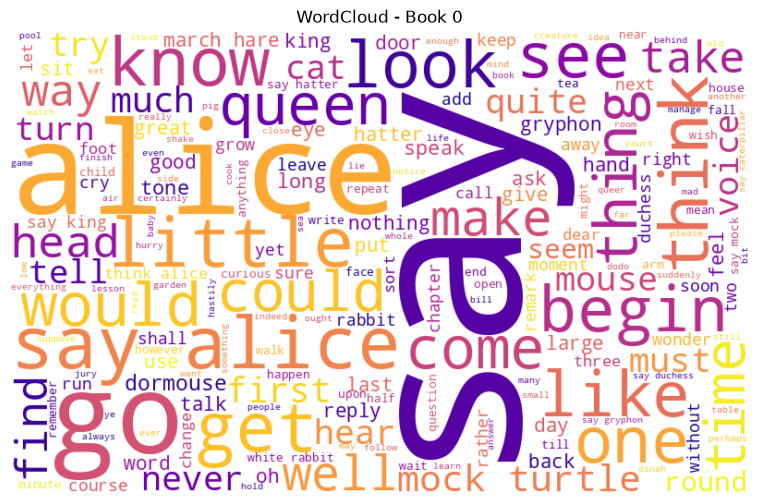

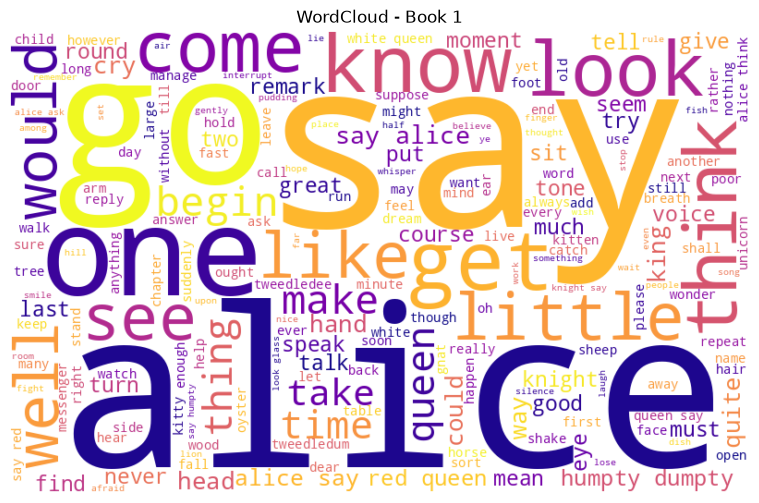

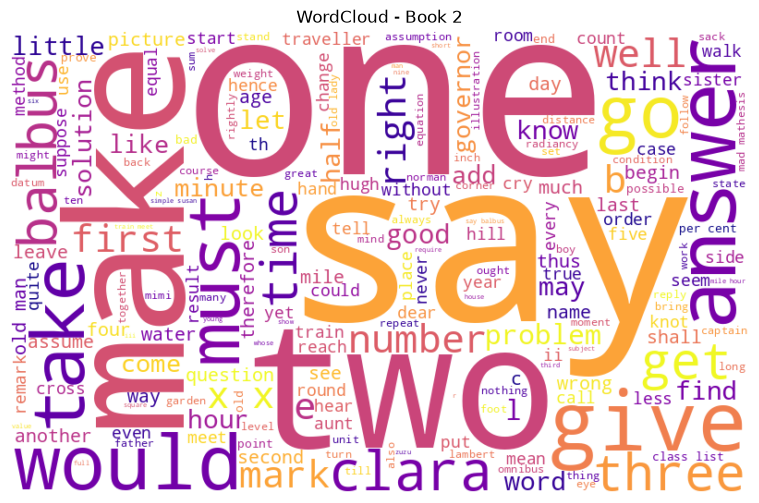

In [11]:
wc_stopwords = set(stop_words)

for i, tokens in enumerate(lemmatized_tokens):
    text_blob = ' '.join(tokens)
    wc = WordCloud(width=800, height=500, background_color='white',
                   stopwords=wc_stopwords, colormap='plasma').generate(text_blob)
    plt.figure(figsize=(10, 6))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'WordCloud - Book {i}')
    plt.show()

In [12]:
lemmas_joined = [' '.join(toks) for toks in lemmatized_tokens]   # the hint's answer

cv = CountVectorizer(min_df=1)
bow = cv.fit_transform(lemmas_joined)
vocab = cv.get_feature_names_out()

bow_df = bow.toarray()
totals = bow_df.sum(axis=0)              # add the three books together
top_idx = totals.argsort()[::-1][:5]     # sort ascending, reverse, take five
top_words = [(vocab[i], totals[i]) for i in top_idx]

print('Top 5 words overall (BoW):', top_words)
print('\nBoW matrix shape:', bow_df.shape)

Top 5 words overall (BoW): [('say', np.int64(1309)), ('alice', np.int64(872)), ('one', np.int64(474)), ('go', np.int64(437)), ('get', np.int64(314))]

BoW matrix shape: (3, 4605)


In [13]:
print(bow[:1])        # the sparse form, for Book 0 only

print('\nReading one row by hand:')
row0 = bow_df[0]
for idx in row0.argsort()[::-1][:5]:
    print(f'  doc 0, column {idx:>5} -> "{vocab[idx]}" appears {row0[idx]} times')

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 1880 stored elements and shape (1, 4605)>
  Coords	Values
  (0, 3805)	2
  (0, 3104)	1
  (0, 1816)	1
  (0, 1256)	1
  (0, 117)	400
  (0, 71)	3
  (0, 4534)	4
  (0, 2008)	1
  (0, 2313)	1
  (0, 584)	1
  (0, 2538)	1
  (0, 1649)	1
  (0, 1264)	3
  (0, 844)	2
  (0, 626)	24
  (0, 3201)	54
  (0, 1928)	6
  (0, 2003)	2
  (0, 3024)	12
  (0, 3990)	2
  (0, 2004)	2
  (0, 600)	4
  (0, 3202)	7
  (0, 2373)	38
  (0, 3964)	6
  :	:
  (0, 3420)	2
  (0, 2672)	1
  (0, 2474)	1
  (0, 674)	1
  (0, 2565)	1
  (0, 719)	1
  (0, 3238)	1
  (0, 3367)	1
  (0, 4439)	1
  (0, 3264)	1
  (0, 4084)	1
  (0, 3568)	1
  (0, 369)	1
  (0, 3572)	1
  (0, 699)	1
  (0, 1472)	1
  (0, 2390)	1
  (0, 599)	1
  (0, 2260)	1
  (0, 1795)	1
  (0, 3366)	1
  (0, 661)	1
  (0, 1684)	1
  (0, 2169)	1
  (0, 1846)	1

Reading one row by hand:
  doc 0, column  3457 -> "say" appears 530 times
  doc 0, column   117 -> "alice" appears 400 times
  doc 0, column  1737 -> "go" appears 180 times
  doc 0, 

Book 0 top BoW words: [('say', 530), ('alice', 400), ('go', 180), ('little', 129), ('think', 128)]


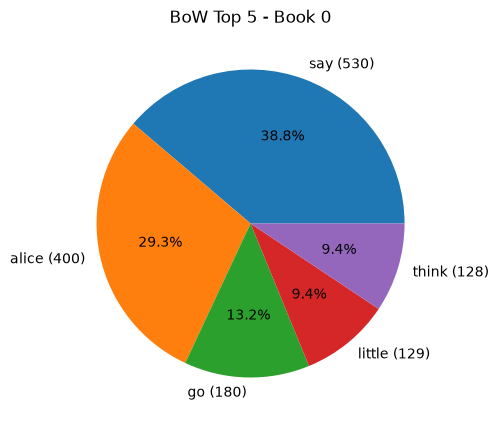

Book 1 top BoW words: [('say', 545), ('alice', 468), ('queen', 190), ('go', 186), ('one', 155)]


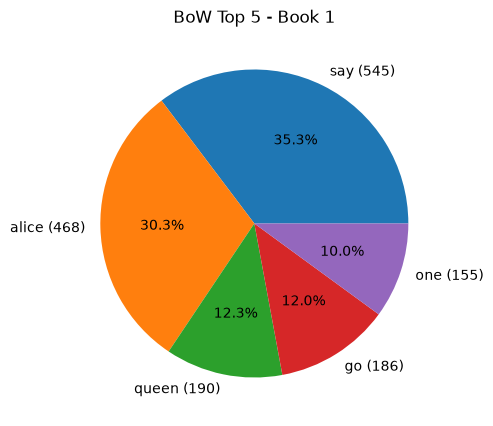

Book 2 top BoW words: [('say', 234), ('one', 214), ('two', 108), ('answer', 101), ('make', 94)]


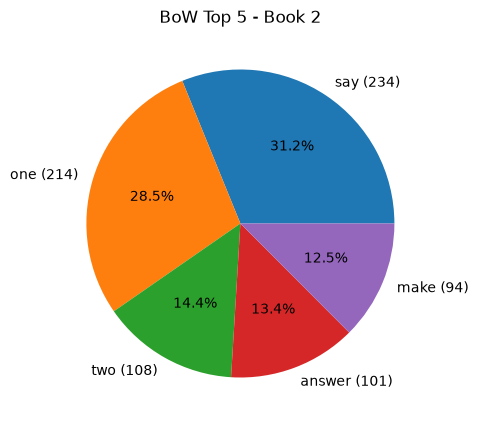

In [14]:
for doc_id, row in enumerate(bow_df):
    top = row.argsort()[::-1][:5]
    pairs = [(vocab[i], int(row[i])) for i in top]
    print(f'Book {doc_id} top BoW words:', pairs)

    plt.figure(figsize=(5, 5))
    labels = [f"{w} ({c})" for w, c in pairs]       # the word AND its count, as asked
    counts = [c for _, c in pairs]
    plt.pie(counts, labels=labels, autopct='%1.1f%%')
    plt.title(f'BoW Top 5 - Book {doc_id}')
    plt.show()

### Analyse the outputs: are those words informative? Are they insightful or expected?

No. They are expected, and that is exactly the problem.

say tops all three books. alice tops two. one, go, little fill the rest. You learned that these are books in which a character called Alice talks — which you knew from the titles.

The words that win are the ones that appear everywhere, and a word that appears everywhere cannot tell two documents apart. Counting rewards exactly the wrong thing.

Look at Book 2 for the proof that the method is not hopeless, only blunt: two and time appear, which are informative — A Tangled Tale is a book of mathematical puzzles. That signal is sitting there under say and one, and the next task is how you dig it out.

In [15]:
tfidf = TfidfVectorizer(min_df=1, max_df=2)
tfidf_mat = tfidf.fit_transform(lemmas_joined).toarray()
vocab_tfidf = tfidf.get_feature_names_out()

print('BoW vocabulary  :', len(vocab))
print('TF-IDF vocabulary:', len(vocab_tfidf))
print("'alice' still in the vocabulary?", 'alice' in set(vocab_tfidf))

for doc_id, row in enumerate(tfidf_mat):
    top = row.argsort()[::-1][:5]
    pairs = [(vocab_tfidf[i], round(float(row[i]), 4)) for i in top]
    print(f'Book {doc_id} top TF-IDF words:', pairs)

BoW vocabulary  : 4605
TF-IDF vocabulary: 3823
'alice' still in the vocabulary? False
Book 0 top TF-IDF words: [('gryphon', 0.3324), ('rabbit', 0.3264), ('turtle', 0.285), ('mock', 0.262), ('hatter', 0.262)]
Book 1 top TF-IDF words: [('humpty', 0.3551), ('dumpty', 0.3551), ('knight', 0.2845), ('tweedledum', 0.2346), ('tweedledee', 0.1839)]
Book 2 top TF-IDF words: [('balbus', 0.3154), ('clara', 0.2799), ('problem', 0.1999), ('train', 0.1791), ('solution', 0.1688)]


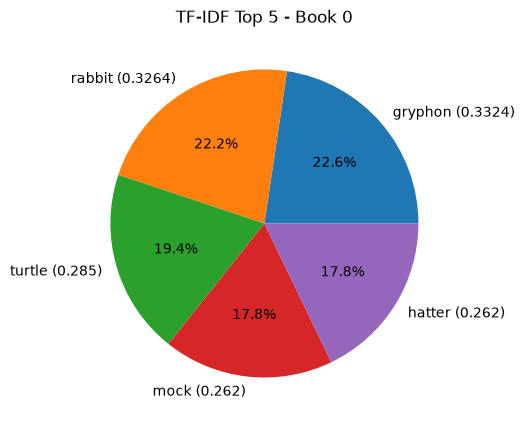

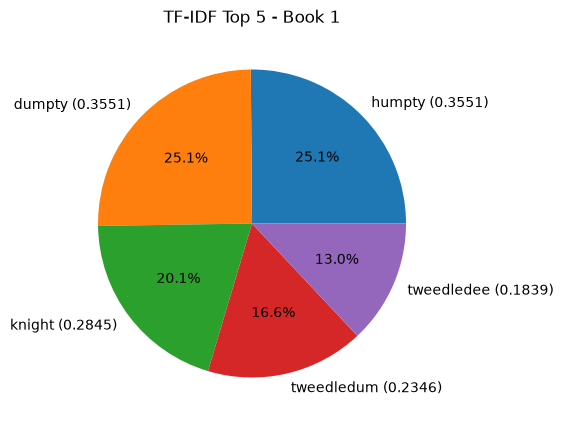

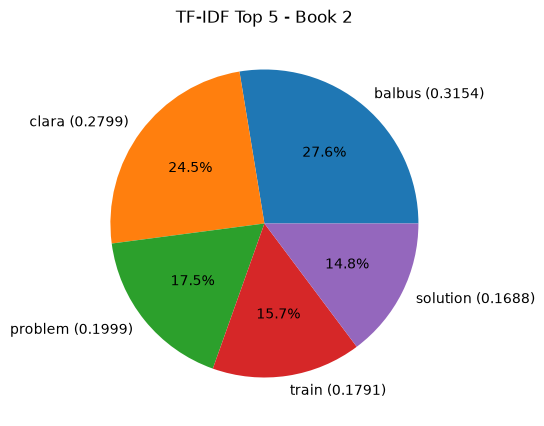

In [16]:
for doc_id, row in enumerate(tfidf_mat):
    top = row.argsort()[::-1][:5]
    pairs = [(vocab_tfidf[i], round(float(row[i]), 4)) for i in top]

    plt.figure(figsize=(5, 5))
    labels = [f"{w} ({s})" for w, s in pairs]
    scores = [s for _, s in pairs]
    plt.pie(scores, labels=labels, autopct='%1.1f%%')
    plt.title(f'TF-IDF Top 5 - Book {doc_id}')
    plt.show()